### **Data Analysis Process**

- **Problem Definition:**
    - Define the Business Problem.
    - Understand the Business Requirements.
    - Define the Analysis Objectives.
- **Data Collection:**
    - Databases, Kaggle, APIs, CSV Files.
- **Data Understanding & Exploration:**
    - Structure, Data Types, Summary Statistics.
- **Data Cleaning & Wrangling:**
    - Handle Duplicates (`duplicated`, `drop_duplicates`).
    - Handle Missing Values (`isnull`, `fillna` with Mean/Mode, `dropna`).
    - Data Type Conversion (`astype`).
    - Rename Columns (`rename`).
- **Exploratory Data Analysis (EDA):**
    - Univariate, Bivariate, Multivariate Analysis.
- **Data Visualization & Business Insights:**
    - Bar charts, Horizontal Bar charts, Pie charts, Scatter plots.

### **1. Import Needed Libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### **2. Load Dataset**
- Load `car_sales_data_dirty.csv` and display the first 5 rows.

In [2]:
df = pd.read_csv('car_sales_data_dirty.csv')
df.head()

  Manufacturer       Model  Engine size  ... Year of manufacture   Mileage    Price
0         Ford      Fiesta          1.0  ...                2002  127300.0   3074.0
1      Porsche  718 Cayman          4.0  ...                2016   57850.0  49704.0
2         Ford      Mondeo          1.6  ...                2014   39190.0  24072.0
3       Toyota        RAV4          1.8  ...                1988  210814.0   1705.0
4           VW        Polo          1.0  ...                2006  127869.0   4101.0

[5 rows x 7 columns]

### **3. Data Understanding & Overview**

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50025 entries, 0 to 50024
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Manufacturer         50025 non-null  str    
 1   Model                49945 non-null  str    
 2   Engine size          49925 non-null  float64
 3   Fuel type            49775 non-null  str    
 4   Year of manufacture  50025 non-null  int64  
 5   Mileage              49825 non-null  float64
 6   Price                49875 non-null  float64
dtypes: float64(3), int64(1), str(3)
memory usage: 2.7 MB


In [4]:
df.describe()

        Engine size  Year of manufacture        Mileage          Price
count  49925.000000         50025.000000   49825.000000   49875.000000
mean       1.773028          2004.209475  112504.907697   13826.730727
std        0.734152             9.645313   71616.434545   16418.209031
min        1.000000          1984.000000     630.000000      76.000000
25%        1.400000          1996.000000   54377.000000    3061.500000
50%        1.600000          2004.000000  101010.000000    7966.000000
75%        2.000000          2012.000000  158624.000000   19021.500000
max        5.000000          2022.000000  453537.000000  168081.000000

In [5]:
df.describe(include='object')

       Manufacturer   Model Fuel type
count         50025   49945     49775
unique            5      15         3
top            Ford  Mondeo    Petrol
freq          14967    5055     25364

### **4. Understanding `count()` vs `value_counts()`**
- Compare between counting non-null values with `count()` and frequency distribution with `value_counts()`.

In [6]:
df['Manufacturer'].count()

np.int64(50025)

In [7]:
df['Manufacturer'].value_counts()

Manufacturer
Ford       14967
VW         14920
Toyota     12564
BMW         4965
Porsche     2609
Name: count, dtype: int64

### **5. Bi-variate Analysis**

In [8]:
df.groupby(['Manufacturer', 'Fuel type']).size().sort_values(ascending=False)

Manufacturer  Fuel type
Toyota        Hybrid       9683
VW            Petrol       8468
Ford          Petrol       8080
VW            Diesel       5866
Ford          Diesel       5801
BMW           Petrol       3672
Toyota        Petrol       2820
Porsche       Petrol       2324
BMW           Diesel       1271
Ford          Hybrid       1005
VW            Hybrid        510
Porsche       Diesel        275
dtype: int64

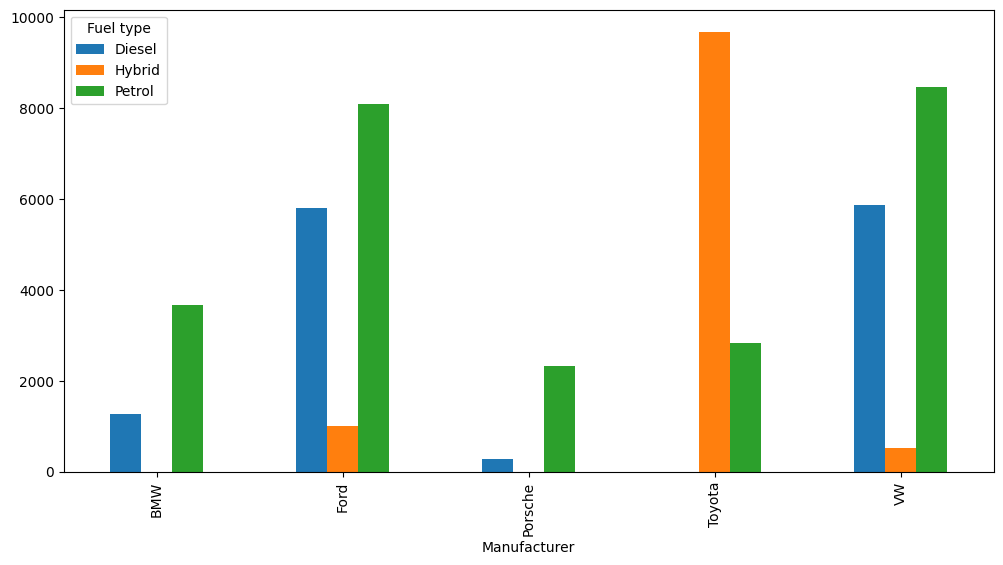

In [9]:
df.groupby(['Manufacturer', 'Fuel type']).size().unstack().plot(kind='bar', figsize=(12, 6))
plt.show()

In [10]:
df.groupby('Manufacturer')['Model'].nunique().reset_index(name='Model Count')

  Manufacturer  Model Count
0          BMW            3
1         Ford            3
2      Porsche            3
3       Toyota            3
4           VW            3

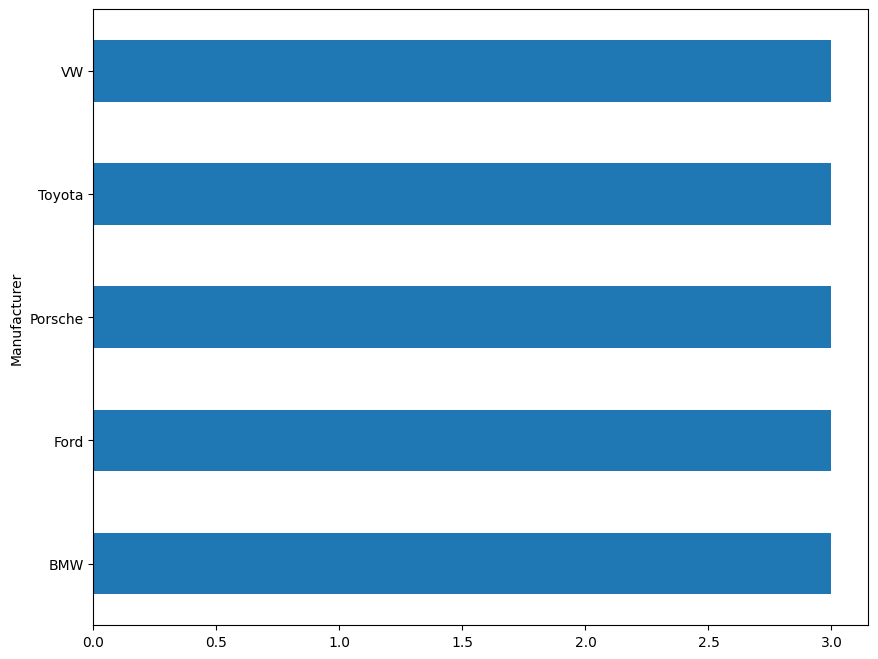

In [11]:
df.groupby('Manufacturer')['Model'].nunique().sort_values().plot(kind='barh', figsize=(10, 8))
plt.show()

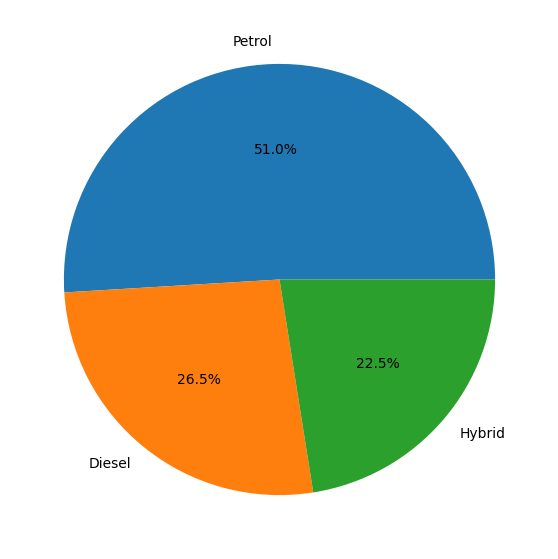

In [12]:
df['Fuel type'].value_counts().plot(kind='pie', autopct='%1.1f%%', figsize=(7, 7))
plt.ylabel('')
plt.show()

In [13]:
df[df['Price'] < 5000].groupby('Manufacturer').size().sort_values(ascending=False)

Manufacturer
VW         6326
Ford       6320
Toyota     4332
BMW        1177
Porsche     451
dtype: int64

In [14]:
df[df['Price'] < 5000].groupby('Fuel type').size().sort_values(ascending=False)

Fuel type
Petrol    10075
Diesel     4755
Hybrid     3684
dtype: int64

In [15]:
df['Mileage'].corr(df['Price']) * 100

np.float64(-63.2627911449651)

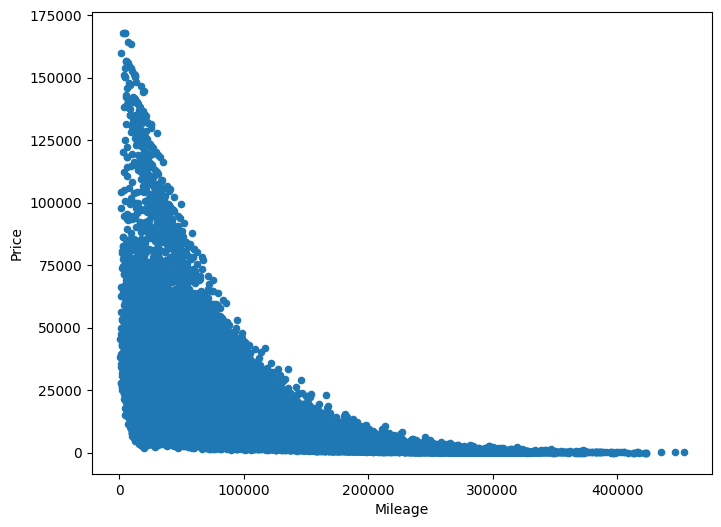

In [16]:
df.plot(kind='scatter', x='Mileage', y='Price', figsize=(8, 6))
plt.show()

### **6. Multi-variate Analysis**

In [17]:
df.groupby(['Manufacturer', 'Year of manufacture'])['Price'].mean()

Manufacturer  Year of manufacture
BMW           1984                    1601.300000
              1985                    1910.454545
              1986                    1920.468085
              1987                    1972.722222
              1988                    2621.837209
                                         ...     
VW            2018                   28106.565815
              2019                   31045.118310
              2020                   33881.325926
              2021                   37614.508876
              2022                   41263.592593
Name: Price, Length: 195, dtype: float64

In [18]:
df.corr(numeric_only=True)

                     Engine size  Year of manufacture   Mileage     Price
Engine size             1.000000            -0.000772  0.004131  0.398599
Year of manufacture    -0.000772             1.000000 -0.807289  0.714252
Mileage                 0.004131            -0.807289  1.000000 -0.632628
Price                   0.398599             0.714252 -0.632628  1.000000

### **7. Data Cleaning & Wrangling**
- **Handle Duplicated Records**
- **Handle Missing Values (Mean & Mode Imputation)**
- **Drop Unnecessary Columns**
- **Data Type Conversion**
- **Rename Columns**

**A. Duplicated Records**

In [19]:
df.duplicated().sum()

np.int64(36)

In [20]:
df[df.duplicated()]

      Manufacturer   Model  Engine size  ... Year of manufacture   Mileage    Price
5426            VW    Polo          1.2  ...                2003   10000.0   8024.0
9862          Ford  Mondeo          1.4  ...                1987  224569.0    883.0
19020       Toyota   Yaris          1.0  ...                1996   13500.0   5087.0
19337           VW    Polo          1.0  ...                2000   11500.0   5950.0
23927           VW    Polo          1.2  ...                2021    1000.0  27901.0
25368           VW    Golf          1.2  ...                2011    6000.0  17401.0
28576           VW    Polo          1.2  ...                2003   10000.0   8024.0
34246           VW  Passat          2.0  ...                2003   10000.0  16087.0
35647         Ford   Focus          1.6  ...                2019    2000.0  39636.0
41536           VW  Passat          1.8  ...                1996   13500.0   9394.0
45904         Ford  Fiesta          1.2  ...                2003  124092.0  

In [21]:
df[df.duplicated(keep=False)]

      Manufacturer   Model  Engine size  ... Year of manufacture   Mileage    Price
199           Ford  Mondeo          1.6  ...                2013   79521.0  17370.0
821             VW    Polo          1.0  ...                1995  168060.0   1420.0
1414            VW    Golf          1.2  ...                1989  121692.0   1801.0
2183          Ford  Mondeo          1.4  ...                1987  224569.0    883.0
4144            VW    Golf          1.6  ...                2005  120820.0   6083.0
...            ...     ...          ...  ...                 ...       ...      ...
50020         Ford   Focus          2.0  ...                2002   39712.0  11587.0
50021       Toyota   Yaris          1.0  ...                2003   80459.0   5376.0
50022           VW    Polo          1.0  ...                1995  168060.0   1420.0
50023         Ford  Fiesta          1.2  ...                1994  102413.0   2386.0
50024         Ford  Mondeo          1.8  ...                1999  120608.0  

In [22]:
df.drop_duplicates(inplace=True)

In [23]:
df.shape

(49989, 7)

**B. Missing Values (Handling with Mean & Mode)**

In [24]:
df.isnull().sum()

Manufacturer             0
Model                   80
Engine size            100
Fuel type              250
Year of manufacture      0
Mileage                200
Price                  150
dtype: int64

In [25]:
df[df.isnull().any(axis=1)]

      Manufacturer       Model  ...   Mileage    Price
148             VW        Polo  ...  225099.0    489.0
327        Porsche  718 Cayman  ...  132662.0      NaN
469        Porsche  718 Cayman  ...       NaN   5991.0
725             VW        Polo  ...       NaN    404.0
833           Ford      Fiesta  ...   61988.0      NaN
...            ...         ...  ...       ...      ...
49715       Toyota         NaN  ...  133875.0  10157.0
49824           VW        Polo  ...       NaN   1843.0
49829         Ford      Mondeo  ...       NaN  17725.0
49938          BMW          M5  ...       NaN  74105.0
49961       Toyota       Yaris  ...       NaN   1127.0

[775 rows x 7 columns]

In [26]:
df[df['Mileage'].isnull()]

      Manufacturer       Model  ...  Mileage    Price
469        Porsche  718 Cayman  ...      NaN   5991.0
725             VW        Polo  ...      NaN    404.0
879             VW        Polo  ...      NaN  11591.0
998             VW      Passat  ...      NaN  32955.0
1003        Toyota        RAV4  ...      NaN  53333.0
...            ...         ...  ...      ...      ...
49609           VW        Golf  ...      NaN  28995.0
49824           VW        Polo  ...      NaN   1843.0
49829         Ford      Mondeo  ...      NaN  17725.0
49938          BMW          M5  ...      NaN  74105.0
49961       Toyota       Yaris  ...      NaN   1127.0

[200 rows x 7 columns]

In [27]:
df['Mileage'] = df['Mileage'].fillna(df['Mileage'].mean())

In [28]:
df['Price'] = df['Price'].fillna(df['Price'].mean())

In [29]:
df['Engine size'] = df['Engine size'].fillna(df['Engine size'].mean())

In [30]:
df['Fuel type'] = df['Fuel type'].fillna(df['Fuel type'].mode()[0])

In [31]:
df['Model'] = df['Model'].fillna(df['Model'].mode()[0])

In [32]:
df.isnull().sum()

Manufacturer           0
Model                  0
Engine size            0
Fuel type              0
Year of manufacture    0
Mileage                0
Price                  0
dtype: int64

**C. Drop Columns**

In [33]:
df.drop(columns=['Engine size'], inplace=True)

**D. Data Type Conversion**

In [34]:
df.dtypes

Manufacturer               str
Model                      str
Fuel type                  str
Year of manufacture      int64
Mileage                float64
Price                  float64
dtype: object

In [35]:
df['Price'] = df['Price'].astype('int64')

**E. Rename Columns**

In [36]:
df.rename(columns={'Manufacturer': 'brand', 'Fuel type': 'fuel'}, inplace=True)

### **8. Summary & Guidelines**
- **Outliers Handling:**
    - Use `quantile()` or IQR to detect extreme values beyond normal range.
    - Use `clip()` to cap outliers within lower and upper bounds.
    - Use boolean indexing or `drop()` to remove extreme outliers.
- **Data Standardization & Formatting:**
    - Use `map()` or `replace()` to format category names and standardize text.
    - Use `str.strip()` to clean column names and remove unwanted whitespace.
    - Use `StandardScaler()` or `MinMaxScaler()` to scale numerical features into unified ranges.